# Ordered Proportional Symbol Chart

**Family:** Ranking &nbsp;|&nbsp; **Library:** matplotlib / seaborn

> *Ranking:* Use when an item's position in an ordered list matters more than its absolute value.

## Design purpose

Circles sized by value and arranged in rank order. It suits values that span a very wide range, where bars for the small items would be too short to see.

## When to use

- Rank items whose values differ by orders of magnitude (company valuations, city populations)
- Make an eye-catching infographic where visual impact matters more than precision

## Avoid when

- Precise comparison is needed (people underestimate area differences)
- Values are similar (the circles all look the same)

## Alternatives

- Ordered bar chart with a log axis
- Packed bubble chart

## Design tips

- Scale circle area (not radius) to value
- Print the value inside or below each circle

## Example

Population of the 10 largest metropolitan areas (millions, approximate).

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

### Data

In [2]:
cities = ["Tokyo", "Delhi", "Shanghai", "Dhaka", "São Paulo", "Cairo", "Mexico City",
          "Beijing", "Mumbai", "Osaka"]
pop = [37.1, 33.8, 29.9, 23.9, 22.8, 22.6, 22.5, 22.2, 21.7, 19.0]
df = pd.DataFrame({"city": cities, "pop_m": pop}).sort_values("pop_m", ascending=False)
df

,city,pop_m
0,Tokyo,37.1
1,Delhi,33.8
2,Shanghai,29.9
3,Dhaka,23.9
4,São Paulo,22.8
5,Cairo,22.6
6,Mexico City,22.5
7,Beijing,22.2
8,Mumbai,21.7
9,Osaka,19.0


### Plot

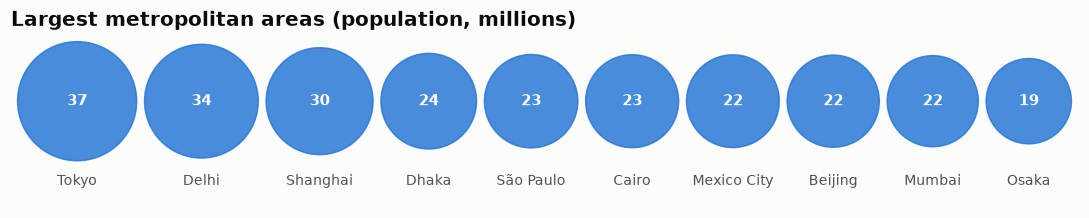

In [3]:
fig, ax = plt.subplots(figsize=(10, 3.4))
r = np.sqrt(df["pop_m"].values / np.pi)            # area proportional to value
r = r / r.max() * 0.45
x = np.cumsum(np.r_[r[0], r[:-1] + r[1:] + 0.06])
for xi, ri, (_, row) in zip(x, r, df.iterrows()):
    ax.add_patch(plt.Circle((xi, 0), ri, color=PALETTE[0], alpha=0.85))
    ax.text(xi, 0, f"{row['pop_m']:.0f}", ha="center", va="center", color="white",
            fontsize=10, weight="bold")
    ax.text(xi, -0.55, row["city"], ha="center", va="top", fontsize=9, color="#52514e")
ax.set_xlim(-0.05, x[-1] + r[-1] + 0.05)
ax.set_ylim(-0.8, 0.5)
ax.set_aspect("equal")
ax.axis("off")
ax.set_title("Largest metropolitan areas (population, millions)")
fig.tight_layout()
plt.show()

---
Standalone script: [`ordered_proportional_symbol.py`](ordered_proportional_symbol.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)